# Resumable YOLO11 Transfer Learning

This notebook audits the dataset, reconstructs a missing baseline when necessary, trains staged transfer-learning candidates, selects exclusively on validation macro-F1, and evaluates the selected model once on the held-out test set. A perfect score is not guaranteed and must not be pursued through test-set tuning.

## 1. Configuration

In [1]:
import hashlib
import json
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from ultralytics import YOLO, __version__ as ultralytics_version

dataset_candidates = [
    Path("../datasets/shoe_brands_preprocessed").resolve(),
    Path("modeling/datasets/shoe_brands_preprocessed").resolve(),
    Path("datasets/shoe_brands_preprocessed").resolve(),
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(f"Dataset not found. Checked: {dataset_candidates}")

MODELING_ROOT = DATASET_ROOT.parents[1]
PROJECT_ROOT = MODELING_ROOT.parent
TRAINING_ROOT = MODELING_ROOT / "runs" / "training"
OUTPUT_ROOT = TRAINING_ROOT / "improvement"
ORIGINAL_BASELINE = TRAINING_ROOT / "baseline" / "weights" / "best.pt"
PRETRAINED_MODEL = "yolo11n-cls.pt"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"train": 193, "val": 55, "test": 27}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = 224
BATCH_SIZE = 32
WORKERS = 0
SEED = 37
DEVICE = 0 if torch.cuda.is_available() else "cpu"

RUN_BASELINE_RECOVERY = True
RUN_HEAD_ONLY = True
RUN_PROGRESSIVE_FINETUNE = True
RUN_BASELINE_FINETUNE = True
FORCE_RETRAIN = False
EXPORT_BEST_ONNX = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Dataset: {DATASET_ROOT}")
print(f"Device: {DEVICE}")
print(f"Output: {OUTPUT_ROOT}")

Dataset: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed
Device: cpu
Output: C:\my-project\shoe-brand-classifier\modeling\runs\training\improvement


## 2. Dataset integrity and leakage audit

In [2]:
image_records = []
corrupt_images = []
for split_name, expected_per_class in EXPECTED_COUNTS.items():
    split_root = DATASET_ROOT / split_name
    actual_classes = sorted(path.name for path in split_root.iterdir() if path.is_dir())
    if actual_classes != EXPECTED_CLASSES:
        raise ValueError(f"Unexpected classes in {split_name}: {actual_classes}")
    for class_name in EXPECTED_CLASSES:
        image_paths = sorted(
            path for path in (split_root / class_name).iterdir()
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        if len(image_paths) != expected_per_class:
            raise ValueError(
                f"Expected {expected_per_class} images in {split_name}/{class_name}; found {len(image_paths)}."
            )
        for image_path in image_paths:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except (OSError, UnidentifiedImageError) as error:
                corrupt_images.append({"path": str(image_path), "error": str(error)})
            image_records.append({
                "split": split_name,
                "class_name": class_name,
                "path": str(image_path),
                "sha256": hashlib.sha256(image_path.read_bytes()).hexdigest(),
            })

image_audit = pd.DataFrame(image_records)
exact_duplicates = image_audit[image_audit.duplicated("sha256", keep=False)].sort_values("sha256")
if corrupt_images:
    raise RuntimeError(f"Corrupt images found: {corrupt_images}")
if not exact_duplicates.empty:
    display(exact_duplicates)
    raise RuntimeError("Exact duplicate images were found. Resolve split leakage before training.")
audit_summary = image_audit.groupby(["split", "class_name"]).size().unstack(fill_value=0)
display(audit_summary)
print(f"Audit passed: {len(image_audit)} valid images and no exact duplicates.")

class_name,adidas,converse,nike
split,,,
test,27,27,27
train,193,193,193
val,55,55,55


Audit passed: 825 valid images and no exact duplicates.


## 3. Reusable training and evaluation functions

In [3]:
def checkpoint_for(run_name: str) -> Path:
    return OUTPUT_ROOT / run_name / "weights" / "best.pt"

def train_if_needed(
    *,
    enabled: bool,
    run_name: str,
    source_checkpoint: str | Path,
    **training_arguments,
) -> Path:
    target_checkpoint = checkpoint_for(run_name)
    if target_checkpoint.is_file() and not FORCE_RETRAIN:
        print(f"Reusing checkpoint: {target_checkpoint}")
        return target_checkpoint
    if not enabled:
        raise FileNotFoundError(f"Training disabled and checkpoint missing: {target_checkpoint}")
    model = YOLO(str(source_checkpoint))
    model.train(
        data=str(DATASET_ROOT),
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        seed=SEED,
        deterministic=True,
        cache=False,
        project=str(OUTPUT_ROOT),
        name=run_name,
        exist_ok=True,
        plots=True,
        **training_arguments,
    )
    if not target_checkpoint.is_file():
        raise FileNotFoundError(f"Training finished without checkpoint: {target_checkpoint}")
    return target_checkpoint

def split_image_paths(split_name: str) -> list[Path]:
    return sorted(
        path for path in (DATASET_ROOT / split_name).rglob("*")
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

def predict_split(checkpoint_path: Path, split_name: str) -> pd.DataFrame:
    model = YOLO(str(checkpoint_path))
    paths = split_image_paths(split_name)
    records = []
    prediction_stream = model.predict(
        source=[str(path) for path in paths],
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        stream=True,
        verbose=False,
    )
    for result in prediction_stream:
        probabilities = result.probs.data.detach().cpu().numpy()
        predicted_index = int(result.probs.top1)
        image_path = Path(result.path)
        record = {
            "image_path": str(image_path),
            "true_label": image_path.parent.name,
            "predicted_label": result.names[predicted_index],
            "confidence": float(result.probs.top1conf.detach().cpu()),
        }
        for class_index, probability in enumerate(probabilities):
            record[f"probability_{result.names[class_index]}"] = float(probability)
        records.append(record)
    frame = pd.DataFrame(records)
    frame["correct"] = frame["true_label"] == frame["predicted_label"]
    return frame

def classification_metrics(frame: pd.DataFrame) -> dict:
    true_labels = frame["true_label"]
    predicted_labels = frame["predicted_label"]
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_precision": precision_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_recall": recall_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "weighted_f1": f1_score(true_labels, predicted_labels, average="weighted", zero_division=0),
    }

## 4. Resumable training stages

If the original baseline checkpoint is missing, Ultralytics downloads `yolo11n-cls.pt` automatically and reconstructs the baseline. Set a stage flag to `False` only when its checkpoint already exists.

In [4]:
if ORIGINAL_BASELINE.is_file():
    baseline_checkpoint = ORIGINAL_BASELINE
    print(f"Using original baseline: {baseline_checkpoint}")
else:
    print("Original baseline checkpoint is missing; reconstructing from YOLO11n pretrained weights.")
    baseline_checkpoint = train_if_needed(
        enabled=RUN_BASELINE_RECOVERY,
        run_name="baseline_recovered",
        source_checkpoint=PRETRAINED_MODEL,
        epochs=30,
        patience=20,
        optimizer="AdamW",
        lr0=1e-3,
        lrf=1e-2,
        weight_decay=5e-4,
        warmup_epochs=3,
        dropout=0.1,
        hsv_h=0.01, hsv_s=0.3, hsv_v=0.2,
        degrees=8.0, translate=0.08, scale=0.2,
        fliplr=0.5, flipud=0.0, cos_lr=True,
    )

head_only_checkpoint = train_if_needed(
    enabled=RUN_HEAD_ONLY,
    run_name="head_only",
    source_checkpoint=PRETRAINED_MODEL,
    epochs=15,
    patience=7,
    freeze=10,
    optimizer="AdamW",
    lr0=1e-3, lrf=0.05, weight_decay=5e-4, dropout=0.15,
    hsv_h=0.005, hsv_s=0.2, hsv_v=0.15,
    degrees=4.0, translate=0.05, scale=0.15, fliplr=0.5,
)

progressive_checkpoint = train_if_needed(
    enabled=RUN_PROGRESSIVE_FINETUNE,
    run_name="progressive_finetune",
    source_checkpoint=head_only_checkpoint,
    epochs=30,
    patience=10,
    optimizer="AdamW",
    lr0=1e-4, lrf=0.1, weight_decay=7e-4, dropout=0.1,
    hsv_h=0.005, hsv_s=0.2, hsv_v=0.15,
    degrees=4.0, translate=0.05, scale=0.15, fliplr=0.5, cos_lr=True,
)

baseline_finetune_checkpoint = train_if_needed(
    enabled=RUN_BASELINE_FINETUNE,
    run_name="baseline_finetune",
    source_checkpoint=baseline_checkpoint,
    epochs=25,
    patience=8,
    optimizer="AdamW",
    lr0=5e-5, lrf=0.1, weight_decay=7e-4, dropout=0.1,
    hsv_h=0.005, hsv_s=0.2, hsv_v=0.15,
    degrees=4.0, translate=0.05, scale=0.15, fliplr=0.5, cos_lr=True,
)
print("All candidate checkpoints are ready.")

Original baseline checkpoint is missing; reconstructing from YOLO11n pretrained weights.
New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed, degrees=8.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, img

## 5. Validation-only model selection

The held-out test split is not accessed in this section.

In [5]:
candidate_checkpoints = {
    "baseline": baseline_checkpoint,
    "head_only": head_only_checkpoint,
    "progressive_finetune": progressive_checkpoint,
    "baseline_finetune": baseline_finetune_checkpoint,
}
validation_predictions = {}
comparison_records = []
for model_name, checkpoint_path in candidate_checkpoints.items():
    predictions = predict_split(checkpoint_path, "val")
    validation_predictions[model_name] = predictions
    metrics = classification_metrics(predictions)
    comparison_records.append({
        "model": model_name,
        "validation_accuracy": metrics["accuracy"],
        "validation_macro_f1": metrics["macro_f1"],
        "checkpoint": str(checkpoint_path),
    })

model_comparison = pd.DataFrame(comparison_records).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
selected_model_name = str(model_comparison.iloc[0]["model"])
selected_checkpoint = Path(model_comparison.iloc[0]["checkpoint"])
display(model_comparison)
print(f"Selected by validation macro-F1: {selected_model_name}")

,model,validation_accuracy,validation_macro_f1,checkpoint
0,baseline,0.921212,0.921088,C:\my-project\shoe-brand-classifier\modeling\r...
1,progressive_finetune,0.903030,0.903048,C:\my-project\shoe-brand-classifier\modeling\r...
2,baseline_finetune,0.903030,0.903042,C:\my-project\shoe-brand-classifier\modeling\r...
3,head_only,0.872727,0.872727,C:\my-project\shoe-brand-classifier\modeling\r...


Selected by validation macro-F1: baseline


## 6. One-time held-out test evaluation

In [6]:
test_predictions = predict_split(selected_checkpoint, "test")
expected_test_images = EXPECTED_COUNTS["test"] * len(EXPECTED_CLASSES)
if len(test_predictions) != expected_test_images:
    raise RuntimeError(f"Expected {expected_test_images} predictions; found {len(test_predictions)}.")
test_metrics = classification_metrics(test_predictions)
test_metrics["selected_model"] = selected_model_name
true_labels = test_predictions["true_label"]
predicted_labels = test_predictions["predicted_label"]
classification_report_frame = pd.DataFrame(classification_report(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, output_dict=True, zero_division=0
)).T
confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=EXPECTED_CLASSES)
confusion_normalized = confusion_matrix(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, normalize="true"
)
misclassifications = test_predictions[~test_predictions["correct"]].sort_values("confidence", ascending=False)
display(pd.Series(test_metrics, name="value").to_frame())
display(classification_report_frame)

,value
accuracy,0.839506
macro_precision,0.84851
macro_recall,0.839506
macro_f1,0.8408
weighted_f1,0.8408
selected_model,baseline


,precision,recall,f1-score,support
adidas,0.814815,0.814815,0.814815,27.000000
converse,0.956522,0.814815,0.880000,27.000000
nike,0.774194,0.888889,0.827586,27.000000
accuracy,0.839506,0.839506,0.839506,0.839506
macro avg,0.848510,0.839506,0.840800,81.000000
weighted avg,0.848510,0.839506,0.840800,81.000000


## 7. Evaluation visualizations

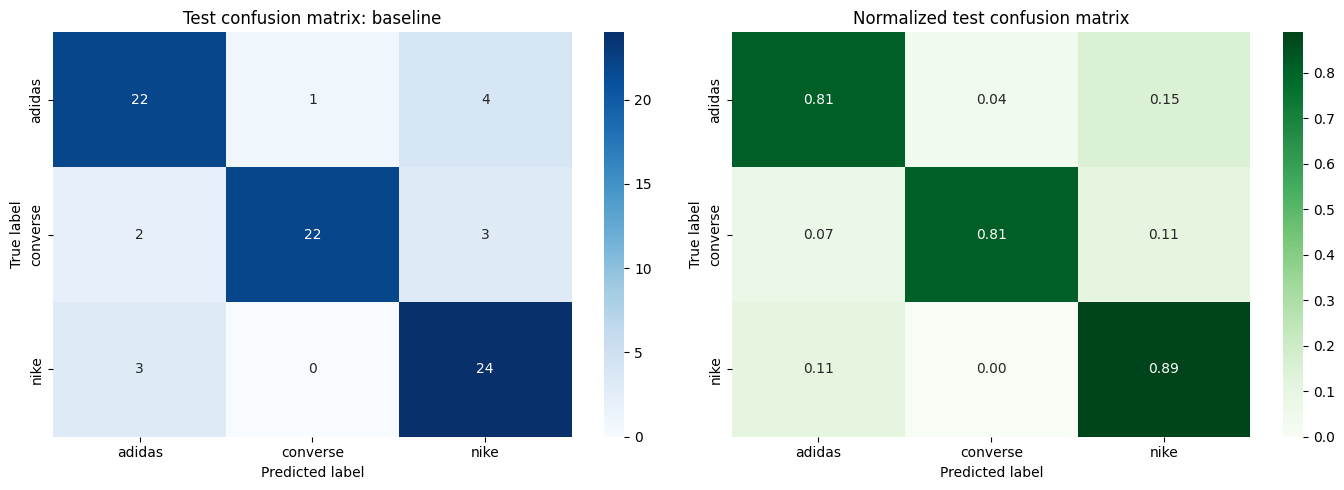

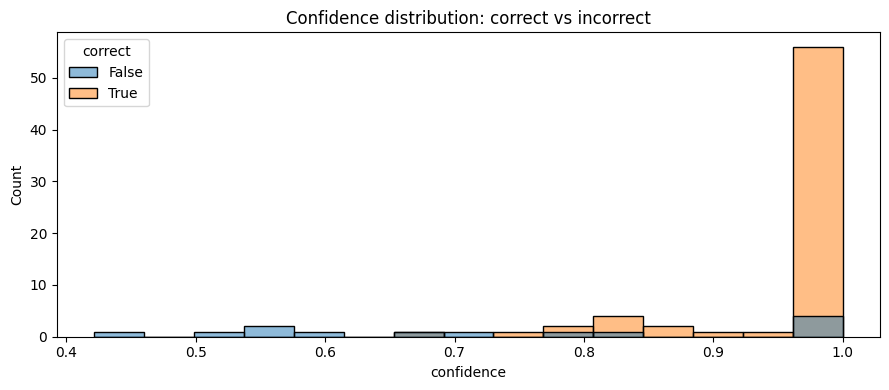

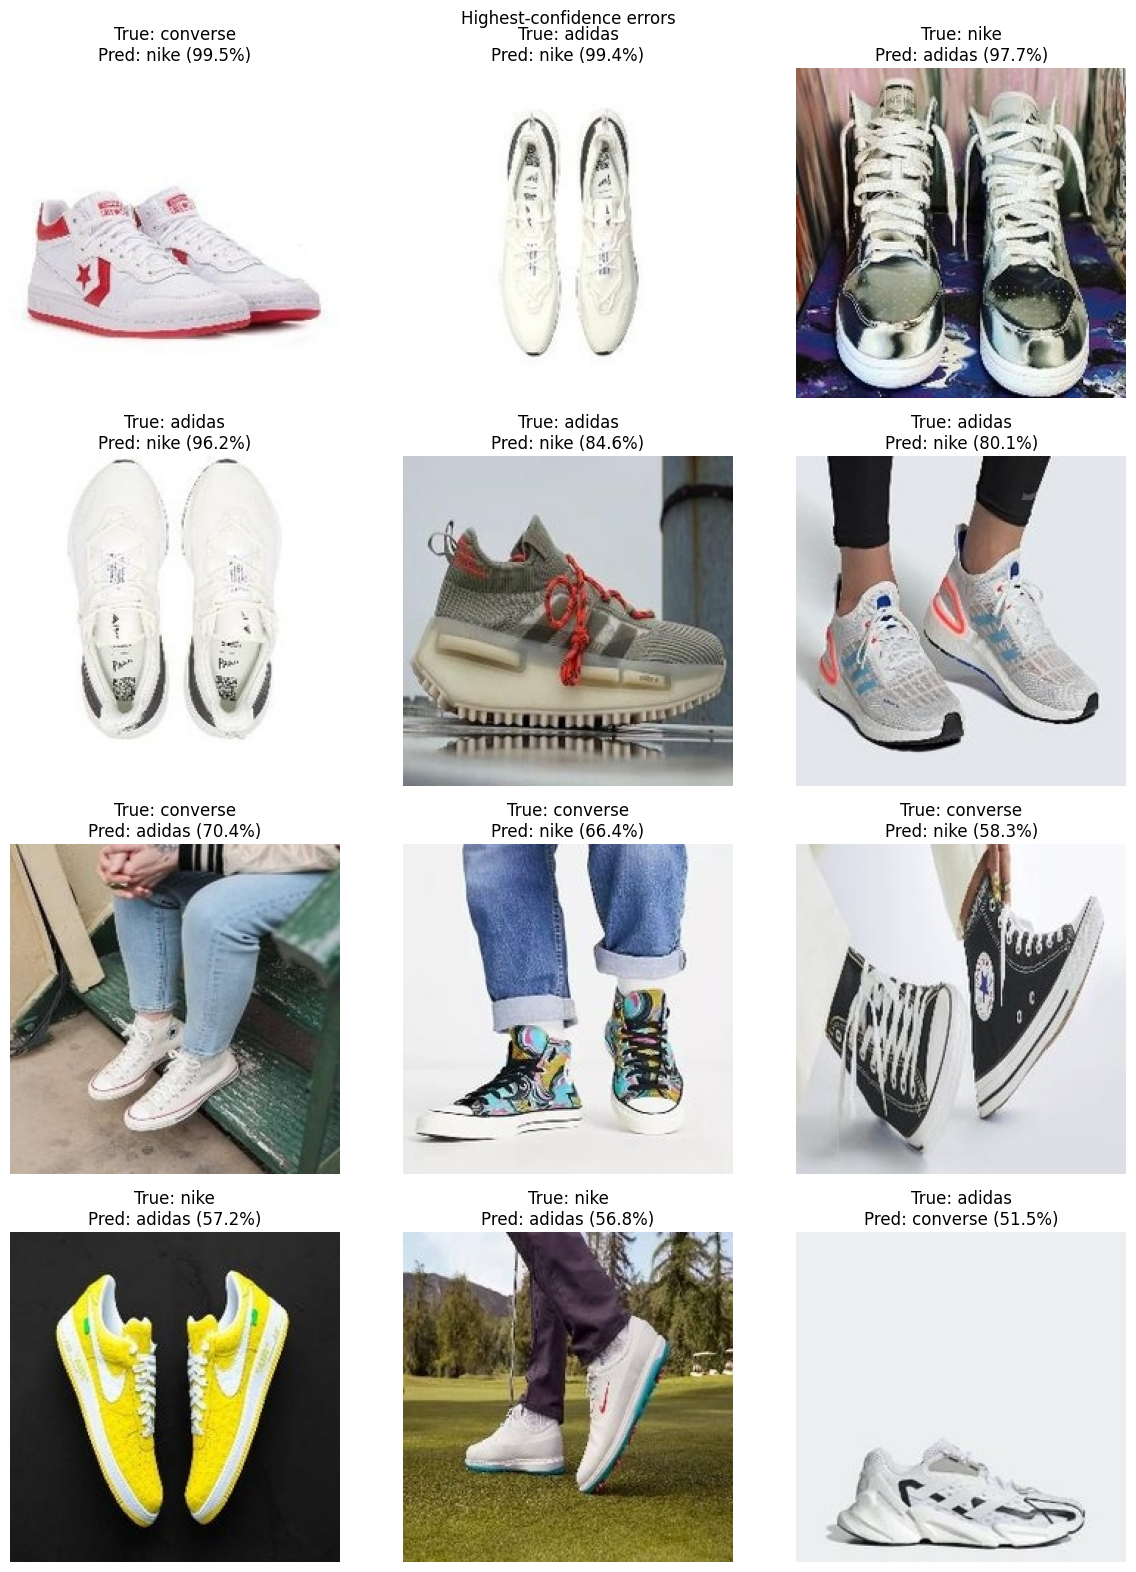

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_counts, annot=True, fmt="d", cmap="Blues", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[0])
sns.heatmap(confusion_normalized, annot=True, fmt=".2f", cmap="Greens", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[1])
axes[0].set_title(f"Test confusion matrix: {selected_model_name}")
axes[1].set_title("Normalized test confusion matrix")
for axis in axes:
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

figure, axis = plt.subplots(figsize=(9, 4))
sns.histplot(data=test_predictions, x="confidence", hue="correct", bins=15, multiple="layer", stat="count", common_norm=False, ax=axis)
axis.set_title("Confidence distribution: correct vs incorrect")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "confidence_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

examples = misclassifications.head(12)
columns = 3
rows = max(1, int(np.ceil(len(examples) / columns)))
figure, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)
for axis, (_, example) in zip(axes.flat, examples.iterrows()):
    with Image.open(example["image_path"]) as image:
        axis.imshow(image)
    axis.set_title(f"True: {example['true_label']}\nPred: {example['predicted_label']} ({example['confidence']:.1%})")
    axis.axis("off")
for axis in axes.flat[len(examples):]:
    axis.axis("off")
figure.suptitle("Highest-confidence errors")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "misclassification_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Save the selected model and reproducible artifacts

In [8]:
BEST_MODEL_PATH = OUTPUT_ROOT / "best_model.pt"
shutil.copy2(selected_checkpoint, BEST_MODEL_PATH)
model_comparison.to_csv(OUTPUT_ROOT / "model_comparison.csv", index=False)
for model_name, predictions in validation_predictions.items():
    predictions.to_csv(OUTPUT_ROOT / f"validation_predictions_{model_name}.csv", index=False)
test_predictions.to_csv(OUTPUT_ROOT / "test_predictions.csv", index=False)
misclassifications.to_csv(OUTPUT_ROOT / "misclassifications.csv", index=False)
classification_report_frame.to_csv(OUTPUT_ROOT / "classification_report.csv")
pd.DataFrame(confusion_counts, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES).to_csv(OUTPUT_ROOT / "confusion_matrix.csv")
with (OUTPUT_ROOT / "metrics_summary.json").open("w", encoding="utf-8") as metrics_file:
    json.dump(test_metrics, metrics_file, indent=2)
manifest = {
    "selected_checkpoint": str(selected_checkpoint),
    "published_checkpoint": str(BEST_MODEL_PATH),
    "selection_metric": "validation_macro_f1",
    "seed": SEED,
    "device": str(DEVICE),
    "ultralytics_version": ultralytics_version,
    "pytorch_version": torch.__version__,
}
with (OUTPUT_ROOT / "experiment_manifest.json").open("w", encoding="utf-8") as manifest_file:
    json.dump(manifest, manifest_file, indent=2)
print(f"Best model: {BEST_MODEL_PATH}")
print(f"Metrics: {OUTPUT_ROOT / 'metrics_summary.json'}")

Best model: C:\my-project\shoe-brand-classifier\modeling\runs\training\improvement\best_model.pt
Metrics: C:\my-project\shoe-brand-classifier\modeling\runs\training\improvement\metrics_summary.json


## 9. Optional ONNX export

In [9]:
if EXPORT_BEST_ONNX:
    export_model = YOLO(str(BEST_MODEL_PATH))
    exported_path = export_model.export(
        format="onnx", imgsz=IMAGE_SIZE, batch=1, dynamic=False, simplify=True, device=DEVICE
    )
    print(f"Exported ONNX model: {exported_path}")
else:
    print("ONNX export skipped. Set EXPORT_BEST_ONNX=True to enable it.")

ONNX export skipped. Set EXPORT_BEST_ONNX=True to enable it.
